# Parte 2 — Entrenamiento y comparación de modelos

Notebook de entrenamiento, evaluación y comparación de modelos.

## Equipo
- Máximo Alva
- Zahir Jacob

## Objetivo

En esta notebook comparamos dos modelos que generan embeddings de rostros. El modelo A es una CNN que diseñamos y entrenamos nosotros con el dataset de la notebook 1, y el modelo B es un modelo preentrenado de InsightFace que usamos sin reentrenar. Los dos se evalúan con el mismo conjunto de test y las mismas métricas.

Seguimos el orden del enunciado:

1. Datos y splits
2. Modelo B (preentrenado)
3. Evaluación: verificación, identificación y elección del umbral
4. Modelo A (CNN propia)
5. Clustering de embeddings, análisis de errores y costo computacional
6. Comparación y elección del modelo
7. Exportación del modelo

Empezamos por el modelo B porque ya viene entrenado. Así podemos armar todo el código de evaluación antes de entrenar el modelo A, y después usamos ese mismo código para evaluarlo.

## Configuración del entorno

Importamos las librerías y definimos las rutas. Los parámetros que comparte con la app (tamaño del rostro, dimensión del embedding y carpeta de modelos) los leemos de `.env.local.example`, como en la notebook 1.

In [1]:
from pathlib import Path
from dotenv import dotenv_values
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import onnx
import onnxruntime as ort
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_fscore_support
import sys
import time
sys.path.insert(0, "src")
from lib.models.custom_cnn import CustomCNN
from lib.augmentation_pipeline import build_train_augmentation
ENV = dotenv_values(".env.local.example")

# Inputs (generados por la notebook 1)
PROCESSED_DIR = Path("./data/processed")
DETECTIONS_FILE = PROCESSED_DIR / "detections.csv"
EMBEDDINGS_FILE = PROCESSED_DIR / "arcface_embeddings.npy"
SPLITS_FILE = PROCESSED_DIR / "splits.csv"

# Modelos
MODELS_DIR = Path(ENV["MODEL_PATH"])
MODELO_B_PATH = MODELS_DIR / "buffalo_l" / "w600k_r50.onnx"

FACE_SIZE = int(ENV["FACE_SIZE"])
EMBEDDING_DIM = int(ENV["EMBEDDING_DIM"])

# Semilla
SEED = 42

F:\ComputerVision\tuia-face-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usar el mismo archivo de configuración que la app evita que la notebook y la app queden con valores distintos, por ejemplo un tamaño de rostro diferente.

## 1. Datos y splits

Usamos los splits que guardamos en la notebook 1 (`splits.csv`). Cada imagen tiene dos particiones:

- `split_open_set`: divide por identidad, 70% train, 15% validación y 15% test. Las personas de validación y test no aparecen en train, que es lo que va a pasar en la app cuando se registre gente nueva. En validación y test, `role_open_set` indica si la imagen es de la galería (las 3 fotos que se registran por persona), una consulta de una persona registrada (`probe_known`) o una consulta de alguien que nunca se registra (`probe_unknown`).
- `split_closed_set`: divide las imágenes de cada persona en 70/15/15, con las mismas personas en las tres partes.

Cada split lo usamos para una sola cosa:

| Split | Uso |
|---|---|
| Open-set train | Entrenar el modelo A |
| Closed-set, solo con las personas de open-set train | Validar el modelo A mientras entrena (curvas y early stopping) |
| Open-set validación | Calibrar el umbral de similitud |
| Open-set test | Evaluar los dos modelos, una sola vez al final |

La columna closed-set incluye a las 995 personas, así que no la usamos sola: si no, entrenaríamos el modelo A con personas que después aparecen en validación y test.

Primero cargamos los splits y le agregamos a cada imagen la fila donde está su embedding en `arcface_embeddings.npy`.

In [2]:
splits = pd.read_csv(SPLITS_FILE)
detections = pd.read_csv(DETECTIONS_FILE, usecols=["image_id", "emb_idx"])
embeddings_b = np.load(EMBEDDINGS_FILE)

# Fila de cada imagen en la matriz de embeddings del modelo B
splits = splits.merge(detections, on="image_id", how="left")
assert splits["emb_idx"].notna().all(), "Hay imágenes sin embedding"
splits["emb_idx"] = splits["emb_idx"].astype(int)

print(f"Imágenes: {len(splits)} | Identidades: {splits['identity'].nunique()}")
print(f"Matriz de embeddings del modelo B: {embeddings_b.shape}")

Imágenes: 25721 | Identidades: 995
Matriz de embeddings del modelo B: (26839, 512)


Las 25.721 imágenes que quedaron después de la limpieza tienen su embedding. La matriz tiene más filas (26.839) porque se calculó antes de la limpieza e incluye también las imágenes que después descartamos. Por eso no usamos la posición de la imagen en la tabla sino la columna `emb_idx`.

Vemos cuántas personas e imágenes hay en cada split y cómo se reparten los roles de validación y test.

In [3]:
resumen = splits.groupby("split_open_set").agg(identidades=("identity", "nunique"), imagenes=("image_id", "size"))
roles = pd.crosstab(splits["split_open_set"], splits["role_open_set"])
resumen.join(roles).fillna(0).astype(int).loc[["train", "val", "test"]]

,identidades,imagenes,gallery,probe_known,probe_unknown
split_open_set,,,,,
train,696,17995,0,0,0
val,149,3794,357,2691,746
test,150,3932,360,2806,766


Train tiene 696 personas y casi 18.000 imágenes, y de ahí salen las fotos con las que entrenamos el modelo A. Validación y test quedaron parecidos, con unas 150 personas cada uno. En test, 120 personas están registradas con 3 fotos cada una (360 imágenes de galería) y tienen 2.806 consultas. Las otras 30 personas no se registran y aportan 766 consultas que el sistema debería rechazar como `unknown`.

En la notebook 1 verificamos que ninguna imagen se repitiera entre train y test. En un split open-set además tienen que estar separadas las personas, así que lo comprobamos para los tres splits.

In [4]:
ids = {s: set(splits.loc[splits["split_open_set"] == s, "identity"]) for s in ["train", "val", "test"]}
assert not ids["train"] & ids["val"], "Identidades compartidas entre train y val"
assert not ids["train"] & ids["test"], "Identidades compartidas entre train y test"
assert not ids["val"] & ids["test"], "Identidades compartidas entre val y test"
print("Sin identidades compartidas entre train, val y test.")

Sin identidades compartidas entre train, val y test.


No hay personas compartidas entre los splits, así que los resultados en validación y test miden cómo funciona cada modelo con personas que no vio durante el entrenamiento.

## 2. Modelo B: InsightFace `buffalo_l`

Como modelo preentrenado usamos el paquete `buffalo_l` de InsightFace, sin reentrenarlo. Es el mismo que usa la app (`MODEL_NAME=buffalo_l/w600k_r50.onnx`). El paquete trae varios modelos, de los cuales usamos dos:

| | Detector | Reconocedor |
|---|---|---|
| Archivo | `det_10g.onnx` | `w600k_r50.onnx` |
| Arquitectura | SCRFD-10GF | ResNet-50 |
| Salida | Caja y 5 puntos clave de cada rostro | Embedding de 512 dimensiones |
| Datos de entrenamiento | WIDER FACE | WebFace600K, con la loss ArcFace |

El detector lo usamos en la notebook 1 para encontrar y alinear los rostros. El reconocedor es el que genera los embeddings que comparamos en esta notebook.

WebFace600K pertenece a la familia de datasets WebFace260M, que se armó descargando de internet fotos de celebridades buscando sus nombres. InsightFace no informa el tamaño exacto de WebFace600K, pero su versión depurada más grande (WebFace42M) tiene 2 millones de personas, contra las 995 de nuestro dataset. InsightFace reporta para este modelo 99,80% en LFW y 97,12% en IJB-C (TAR con FAR = 1e-4).

El reconocedor recibe el rostro alineado de 112×112 en RGB, con los píxeles llevados al rango [-1, 1] (restando 127,5 y dividiendo por 127,5). El embedding se normaliza para que tenga norma 1, y así la similitud coseno entre dos embeddings es su producto interno.

En cuanto a la licencia, el código de InsightFace es MIT, pero los modelos preentrenados solo se pueden usar con fines no comerciales o de investigación. Para este trabajo práctico no hay problema, pero para un uso comercial habría que conseguir otra licencia o usar un modelo propio.

Hay que tener en cuenta que CelebA también está formado por fotos de celebridades. Es posible que algunas personas de nuestro test estén entre las que se usaron para entrenar este modelo. No lo podemos verificar, pero si pasa, los resultados del modelo B sobre CelebA serían algo mejores que con personas que nunca vio.

Medimos el tamaño del archivo y la cantidad de parámetros del reconocedor, y vemos qué forma tienen su entrada y su salida. Estos datos los usamos después en la comparación de costo computacional.

In [5]:
modelo_b = onnx.load(MODELO_B_PATH)
n_parametros_b = sum(int(np.prod(w.dims)) for w in modelo_b.graph.initializer)

sesion_b = ort.InferenceSession(str(MODELO_B_PATH), providers=["CPUExecutionProvider"])
entrada_b, salida_b = sesion_b.get_inputs()[0], sesion_b.get_outputs()[0]

pd.Series({
    "Archivo": MODELO_B_PATH.name,
    "Tamaño (MB)": round(MODELO_B_PATH.stat().st_size / 1e6, 1),
    "Parámetros (millones)": round(n_parametros_b / 1e6, 1),
    "Entrada": entrada_b.shape,
    "Salida (embedding)": salida_b.shape,
}, name="Modelo B").to_frame()

,Modelo B
Archivo,w600k_r50.onnx
Tamaño (MB),174.4
Parámetros (millones),43.6
Entrada,"[None, 3, 112, 112]"
Salida (embedding),"[1, 512]"


El reconocedor pesa 174 MB y tiene 43,6 millones de parámetros. La entrada es un lote de imágenes de 3 canales de 112×112 (el `None` indica que el tamaño del lote es variable) y la salida es un vector de 512 valores por imagen.

### Extracción de embeddings

Los embeddings del modelo B ya los calculamos en la notebook 1, durante la detección y alineación, y están en `arcface_embeddings.npy`. Antes de usarlos comprobamos que tengan 512 dimensiones y norma 1.

In [6]:
normas = np.linalg.norm(embeddings_b, axis=1)
assert embeddings_b.shape[1] == EMBEDDING_DIM
print(f"Dimensión: {embeddings_b.shape[1]} | Norma mínima: {normas.min():.4f} | Norma máxima: {normas.max():.4f}")

Dimensión: 512 | Norma mínima: 1.0000 | Norma máxima: 1.0000


Todos los embeddings tienen 512 dimensiones y norma 1, así que para compararlos alcanza con el producto interno.

También queremos asegurarnos de que estos embeddings sean iguales a los que calcula la app. El umbral que elijamos en esta notebook va a ir al `.env` de la app, y si la app preprocesara los rostros de otra forma, ese umbral no le serviría. Para comprobarlo, tomamos 50 rostros alineados, recalculamos su embedding con el mismo preprocesamiento que `FaceService.extract_embedding_from_face` y lo comparamos con el guardado.

In [7]:
def embedding_modelo_b(rostro_bgr: np.ndarray) -> np.ndarray:
    """Embedding del modelo B, preprocesando igual que la app."""
    # BGR -> RGB, (x - 127.5) / 127.5, HWC -> NCHW
    blob = cv2.dnn.blobFromImage(rostro_bgr, scalefactor=1.0 / 127.5, size=(FACE_SIZE, FACE_SIZE),
                                 mean=(127.5, 127.5, 127.5), swapRB=True)
    emb = sesion_b.run(None, {entrada_b.name: blob})[0][0]
    return emb / np.linalg.norm(emb)


muestra = splits.sample(50, random_state=SEED)
recalculados = np.stack([embedding_modelo_b(cv2.imread(p)) for p in muestra["aligned_path"]])
similitudes = (recalculados * embeddings_b[muestra["emb_idx"]]).sum(axis=1)
print(f"Similitud coseno entre embedding guardado y recalculado ({len(muestra)} rostros): "
      f"mínima {similitudes.min():.4f}, media {similitudes.mean():.4f}")

Similitud coseno entre embedding guardado y recalculado (50 rostros): mínima 1.0000, media 1.0000


La similitud dio 1 en los 50 rostros: los embeddings guardados son los mismos que calcula la app. Entonces podemos evaluar el modelo B con los embeddings de la notebook 1, y el umbral que calibremos va a servir en la app.

## 3. Evaluación

Los dos modelos se evalúan sobre sus embeddings y con el mismo protocolo. Escribimos el código como funciones que reciben la matriz de embeddings, para usarlas igual con el modelo B y con el modelo A.

El protocolo tiene tres partes: verificación (¿dos fotos son de la misma persona?), identificación (¿quién es la persona de la foto?) y elección del umbral de similitud que usa la app.

### a) Verificación

Para medir la verificación armamos pares de imágenes del test. Un par es genuino si las dos imágenes son de la misma persona e impostor si son de personas distintas. A cada par le calculamos la similitud coseno, y un buen modelo tiene que darles similitudes altas a los pares genuinos y bajas a los impostores.

Usamos todos los pares genuinos posibles del test y la misma cantidad de pares impostores, elegidos al azar con la semilla, para que las dos clases queden balanceadas como pide el enunciado. No usamos todos los impostores porque son muchos más (casi todas las combinaciones de dos fotos son de personas distintas). Para la verificación usamos todas las imágenes del test, sin importar su rol en la identificación.

In [8]:
def generar_pares(df: pd.DataFrame, seed: int = SEED) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Todos los pares genuinos del split y la misma cantidad de impostores al azar."""
    identidades = df["identity"].to_numpy()
    i, j = np.triu_indices(len(df), k=1)  # todas las combinaciones de dos imágenes distintas
    misma_persona = identidades[i] == identidades[j]

    i_gen, j_gen = i[misma_persona], j[misma_persona]
    i_imp, j_imp = i[~misma_persona], j[~misma_persona]

    # Tantos impostores como genuinos, elegidos al azar
    elegidos = np.random.default_rng(seed).choice(len(i_imp), size=len(i_gen), replace=False)
    i_imp, j_imp = i_imp[elegidos], j_imp[elegidos]

    etiquetas = np.r_[np.ones(len(i_gen), dtype=int), np.zeros(len(i_imp), dtype=int)]
    return np.r_[i_gen, i_imp], np.r_[j_gen, j_imp], etiquetas


test = splits[splits["split_open_set"] == "test"].reset_index(drop=True)
par_a_test, par_b_test, etiquetas_test = generar_pares(test)
print(f"Pares del test: {len(etiquetas_test)} ({etiquetas_test.sum()} genuinos y {(etiquetas_test == 0).sum()} impostores)")

Pares del test: 100990 (50495 genuinos y 50495 impostores)


Salieron unos 50.000 pares de cada tipo. Tener tantos impostores es importante para medir un FAR chico: con FAR = 1e-3, el umbral deja pasar 1 de cada 1.000 impostores, o sea unos 50 pares. Con pocos pares ese número dependería de uno o dos casos y sería muy inestable.

Ahora calculamos las métricas de verificación a partir de las similitudes de los pares:

- FAR: porcentaje de impostores aceptados. FRR: porcentaje de genuinos rechazados. TAR = 1 - FRR.
- Curva ROC: el TAR en función del FAR, recorriendo todos los umbrales posibles, y su área (AUC).
- EER: el error en el umbral donde FAR y FRR son iguales.
- TAR @ FAR: el TAR con el umbral que da un FAR de 1e-2 y de 1e-3, los valores que pide el enunciado.

Para la ROC usamos `roc_curve` de scikit-learn, que devuelve el FAR y el TAR para cada umbral.

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score


def similitudes_pares(embeddings: np.ndarray, par_a: np.ndarray, par_b: np.ndarray) -> np.ndarray:
    """Similitud coseno de cada par (los embeddings tienen norma 1)."""
    return (embeddings[par_a] * embeddings[par_b]).sum(axis=1)


def metricas_verificacion(similitudes: np.ndarray, etiquetas: np.ndarray, fars=(1e-2, 1e-3)) -> dict:
    """AUC, EER y TAR @ FAR a partir de las similitudes de los pares."""
    far, tar, umbrales = roc_curve(etiquetas, similitudes)
    frr = 1 - tar

    # EER: el punto de la curva donde FAR y FRR están más cerca
    i_eer = np.argmin(np.abs(far - frr))
    metricas = {"AUC": roc_auc_score(etiquetas, similitudes),
                "EER": (far[i_eer] + frr[i_eer]) / 2,
                "Umbral EER": umbrales[i_eer]}

    # TAR @ FAR: el mayor TAR cuyo FAR no supera el objetivo
    for objetivo in fars:
        i = np.searchsorted(far, objetivo, side="right") - 1
        metricas[f"TAR @ FAR={objetivo:g}"] = tar[i]

    metricas["curva"] = (far, tar, umbrales)
    return metricas


embeddings_b_test = embeddings_b[test["emb_idx"].to_numpy()]
similitudes_b_test = similitudes_pares(embeddings_b_test, par_a_test, par_b_test)
verificacion_b = metricas_verificacion(similitudes_b_test, etiquetas_test)

pd.Series({k: v for k, v in verificacion_b.items() if k != "curva"}, name="Modelo B").to_frame().round(5)

,Modelo B
AUC,0.99996
EER,0.00236
Umbral EER,0.19663
TAR @ FAR=0.01,0.99933
TAR @ FAR=0.001,0.99582


El modelo B separa casi perfectamente los pares del test. El AUC es 0,99996 y el EER es 0,24%: en el umbral donde los dos errores se igualan (similitud 0,20), se equivoca en 2 o 3 pares de cada 1.000. Aun exigiendo un FAR de 1e-3, acepta el 99,6% de los pares genuinos.

Son valores parecidos a los que reporta InsightFace en benchmarks como LFW. Puede influir lo que mencionamos antes: la limpieza de la notebook 1 usó este mismo modelo y algunas personas de CelebA podrían estar en sus datos de entrenamiento.

Graficamos el histograma de similitudes de los pares genuinos e impostores y la curva ROC. En la ROC usamos escala logarítmica para el FAR, porque los valores que nos interesan (1e-2 y 1e-3) quedarían pegados al cero en escala lineal.

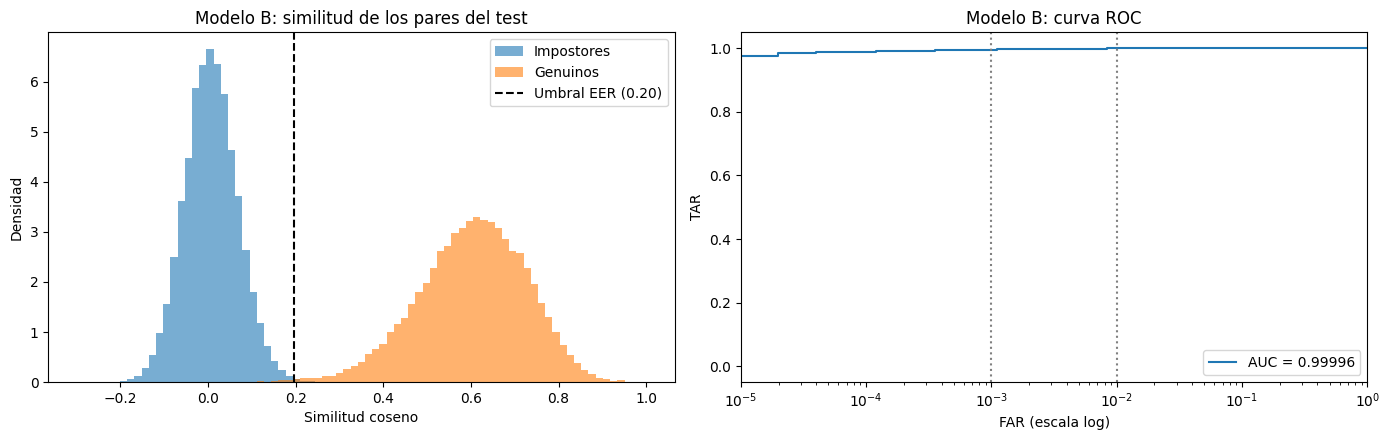

In [10]:
def graficar_verificacion(similitudes: np.ndarray, etiquetas: np.ndarray, metricas: dict, nombre: str):
    """Histograma de similitudes de genuinos e impostores y curva ROC."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    bins = np.linspace(-0.3, 1, 80)
    axes[0].hist(similitudes[etiquetas == 0], bins=bins, alpha=0.6, density=True, label="Impostores")
    axes[0].hist(similitudes[etiquetas == 1], bins=bins, alpha=0.6, density=True, label="Genuinos")
    axes[0].axvline(metricas["Umbral EER"], color="black", linestyle="--",
                    label=f"Umbral EER ({metricas['Umbral EER']:.2f})")
    axes[0].set(title=f"{nombre}: similitud de los pares del test", xlabel="Similitud coseno", ylabel="Densidad")
    axes[0].legend()

    far, tar, _ = metricas["curva"]
    axes[1].plot(far, tar, label=f"AUC = {metricas['AUC']:.5f}")
    for objetivo in (1e-2, 1e-3):
        axes[1].axvline(objetivo, color="gray", linestyle=":")
    axes[1].set(xscale="log", xlim=(1e-5, 1), title=f"{nombre}: curva ROC", xlabel="FAR (escala log)", ylabel="TAR")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


graficar_verificacion(similitudes_b_test, etiquetas_test, verificacion_b, "Modelo B")

En el histograma, las similitudes de los impostores se concentran cerca de 0 y las de los genuinos alrededor de 0,6, con muy poca superposición entre las dos. En la ROC, el TAR queda por encima de 0,97 en todo el rango, incluso en el FAR más chico que podemos medir con 50.000 impostores (un solo impostor aceptado, 2e-5). Las líneas punteadas marcan los FAR de 1e-2 y 1e-3.

### c) Elección del umbral

Hacemos esta parte antes que la identificación porque la identificación necesita el umbral para decidir qué consultas son `unknown`. El umbral lo elegimos con la validación, y en el test solo lo aplicamos.

Podríamos usar el umbral del EER de la verificación, pero ese umbral equilibra los errores cuando se compara una foto contra otra. La app compara cada consulta contra todas las fotos registradas y se queda con la más parecida, así que a un desconocido le alcanza con parecerse a una sola de ellas para recibir un nombre. Con cientos de fotos en la galería, un FAR chico por comparación se convierte en un FAR mucho más grande por consulta.

Por eso calibramos el umbral simulando la app sobre la validación, que tiene su propia galería, consultas de personas registradas y consultas de desconocidos. Para cada consulta buscamos la foto de la galería más parecida, igual que `FaceService.identify`, y para cada umbral medimos:

- FAR de la app: porcentaje de consultas de desconocidos que reciben un nombre.
- FRR de la app: porcentaje de consultas de personas registradas que reciben `unknown`.

Como criterio elegimos el umbral más bajo que deja el FAR de la app en 1% o menos. Preferimos que la app diga `unknown` de más antes que ponerle el nombre de otra persona a alguien que no está registrado.

In [11]:
def simular_app(df: pd.DataFrame, embeddings: np.ndarray) -> pd.DataFrame:
    """Busca para cada consulta la foto más parecida de la galería, como hace la app."""
    es_galeria = (df["role_open_set"] == "gallery").to_numpy()
    similitudes = embeddings[~es_galeria] @ embeddings[es_galeria].T  # consultas x galería

    consultas = df[~es_galeria].copy()
    consultas["score"] = similitudes.max(axis=1)
    consultas["prediccion"] = df.loc[es_galeria, "identity"].to_numpy()[similitudes.argmax(axis=1)]
    consultas["desconocido"] = consultas["role_open_set"] == "probe_unknown"
    return consultas


val = splits[splits["split_open_set"] == "val"].reset_index(drop=True)
embeddings_b_val = embeddings_b[val["emb_idx"].to_numpy()]
consultas_b_val = simular_app(val, embeddings_b_val)

print(f"Fotos en la galería de validación: {(val['role_open_set'] == 'gallery').sum()}")
print(f"Consultas: {len(consultas_b_val)} ({(~consultas_b_val['desconocido']).sum()} de personas registradas "
      f"y {consultas_b_val['desconocido'].sum()} de desconocidos)")

Fotos en la galería de validación: 357
Consultas: 3437 (2691 de personas registradas y 746 de desconocidos)


Cada consulta se compara contra las 357 fotos de la galería de validación. Hay 746 consultas de desconocidos, así que un FAR de 1% equivale a 7 consultas. Es una estimación con pocos casos: un desconocido más o menos aceptado mueve el FAR en 0,13%.

Calculamos el FAR y el FRR de la app para una grilla de umbrales y elegimos el umbral según el criterio. Lo redondeamos hacia arriba a dos decimales para configurarlo en el `.env`. Redondear hacia arriba hace el umbral un poco más estricto, así que el FAR sigue cumpliendo el objetivo.

En el gráfico marcamos también el umbral del EER de la verificación (calculado con pares de validación) y el valor provisorio que tiene hoy la app (`SIMILARITY_THRESHOLD=0.55`), para comparar.

,Umbral,FAR app (%),FRR app (%)
,,,
Umbral elegido,0.31,0.80,0.19
EER verificación,0.19,53.62,0.00
Valor actual de la app,0.55,0.00,15.01


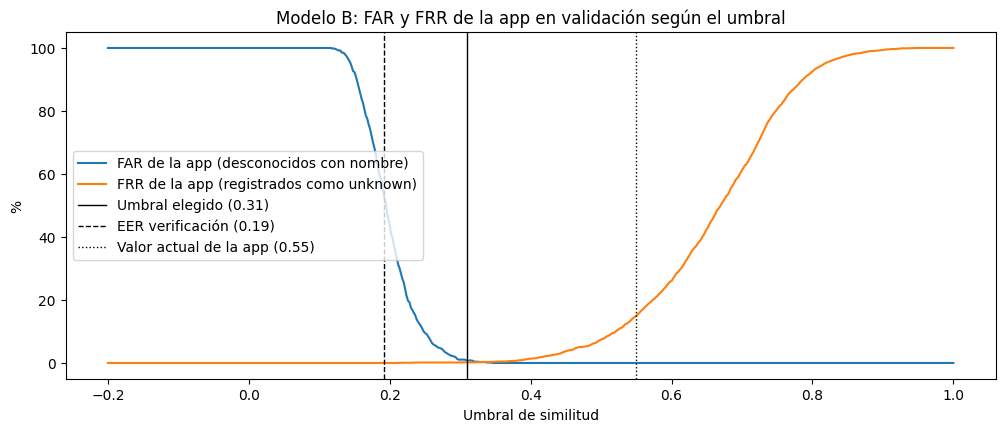

In [12]:
FAR_OBJETIVO = 0.01


def curvas_app(consultas: pd.DataFrame, umbrales: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """FAR y FRR de la app para cada umbral."""
    score_desc = consultas.loc[consultas["desconocido"], "score"].to_numpy()
    score_reg = consultas.loc[~consultas["desconocido"], "score"].to_numpy()
    far = (score_desc[None, :] >= umbrales[:, None]).mean(axis=1)
    frr = (score_reg[None, :] < umbrales[:, None]).mean(axis=1)
    return far, frr


def elegir_umbral(consultas: pd.DataFrame, far_objetivo: float = FAR_OBJETIVO) -> float:
    """Umbral más bajo (redondeado hacia arriba a dos decimales) con FAR de la app <= far_objetivo."""
    candidatos = np.round(np.arange(-1, 1.001, 0.01), 2)
    far, _ = curvas_app(consultas, candidatos)
    return float(candidatos[np.argmax(far <= far_objetivo)])


umbral_b = elegir_umbral(consultas_b_val)

# Umbral del EER de la verificación, con pares de validación
par_a_val, par_b_val, etiquetas_val = generar_pares(val)
umbral_eer_b_val = metricas_verificacion(similitudes_pares(embeddings_b_val, par_a_val, par_b_val), etiquetas_val)["Umbral EER"]

umbrales = np.linspace(-0.2, 1, 601)
far_app, frr_app = curvas_app(consultas_b_val, umbrales)
comparacion = {"Umbral elegido": umbral_b, "EER verificación": umbral_eer_b_val, "Valor actual de la app": 0.55}

filas = []
for nombre, u in comparacion.items():
    far_u, frr_u = curvas_app(consultas_b_val, np.array([u]))
    filas.append({"": nombre, "Umbral": round(u, 2), "FAR app (%)": far_u[0] * 100, "FRR app (%)": frr_u[0] * 100})
display(pd.DataFrame(filas).set_index("").round(2))

plt.figure(figsize=(12, 4.5))
plt.plot(umbrales, far_app * 100, label="FAR de la app (desconocidos con nombre)")
plt.plot(umbrales, frr_app * 100, label="FRR de la app (registrados como unknown)")
for (nombre, u), estilo in zip(comparacion.items(), ["-", "--", ":"]):
    plt.axvline(u, color="black", linestyle=estilo, linewidth=1, label=f"{nombre} ({u:.2f})")
plt.xlabel("Umbral de similitud")
plt.ylabel("%")
plt.title("Modelo B: FAR y FRR de la app en validación según el umbral")
plt.legend()
plt.show()

Con este criterio el umbral queda en 0,31. En validación, 6 de los 746 desconocidos (0,8%) reciben un nombre, y solo el 0,19% de las consultas de personas registradas queda como `unknown`.

Con el umbral del EER de la verificación (0,19), más de la mitad de los desconocidos (53,6%) recibiría el nombre de alguien registrado. Esto confirma que el EER no sirve para elegir el umbral de la app. Con el valor que tiene hoy la app (0,55) ningún desconocido recibe un nombre, pero el 15% de las consultas de personas registradas no se reconoce.

En el gráfico se ve que entre 0,31 y 0,40 los dos errores quedan por debajo del 1,5%. Elegimos el extremo más bajo de esa zona porque es el que menos rechaza a las personas registradas y cumple el objetivo. Este es el umbral que usamos en la identificación del test y el que va a ir al `.env` de la app si elegimos el modelo B.

### b) Identificación

Ahora evaluamos la identificación en el test, con el umbral de 0,31 que elegimos en validación y sin cambiarlo. La galería del test tiene 3 fotos por cada una de las 120 personas registradas, y las consultas son el resto de sus fotos más las de las 30 personas que nunca se registran.

Para cada consulta ordenamos a las personas registradas según la similitud con su foto más parecida de la galería. Es el mismo criterio que la app, que se queda con el embedding más parecido de todos los registrados.

In [13]:
def ranking_identidades(df: pd.DataFrame, embeddings: np.ndarray) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:
    """Similitud de cada consulta con cada persona registrada (su foto más parecida de la galería)."""
    es_galeria = (df["role_open_set"] == "gallery").to_numpy()
    similitudes = embeddings[~es_galeria] @ embeddings[es_galeria].T  # consultas x fotos de galería

    ids_galeria = df.loc[es_galeria, "identity"].to_numpy()
    registrados = np.unique(ids_galeria)
    por_persona = np.stack([similitudes[:, ids_galeria == i].max(axis=1) for i in registrados], axis=1)

    consultas = df[~es_galeria].reset_index(drop=True)
    return consultas, registrados, por_persona


consultas_test, registrados_test, similitud_b_test = ranking_identidades(test, embeddings_b_test)
print(f"Personas registradas: {len(registrados_test)} | Consultas: {len(consultas_test)}")

Personas registradas: 120 | Consultas: 3572


Hay 3.572 consultas para comparar contra las 120 personas registradas: 2.806 de personas registradas y 766 de desconocidos.

Primero medimos Top-1 y Top-5 con las consultas de personas registradas. Una consulta es acierto en Top-k si la persona correcta está entre las k primeras del ranking. Estas dos métricas no usan el umbral: miden si el modelo encuentra a la persona correcta entre las registradas.

In [14]:
def top_k(consultas: pd.DataFrame, registrados: np.ndarray, similitud: np.ndarray, k: int) -> float:
    """Porcentaje de consultas de registrados con la persona correcta entre las k más parecidas."""
    conocidas = (consultas["role_open_set"] == "probe_known").to_numpy()
    mejores_k = registrados[np.argsort(-similitud[conocidas], axis=1)[:, :k]]
    return (mejores_k == consultas.loc[conocidas, "identity"].to_numpy()[:, None]).any(axis=1).mean()


for k in (1, 5):
    print(f"Top-{k}: {100 * top_k(consultas_test, registrados_test, similitud_b_test, k):.2f}%")

Top-1: 100.00%
Top-5: 100.00%


El modelo B acierta el 100% en Top-1 y en Top-5: en todas las consultas de personas registradas, la persona más parecida es la correcta. Como el Top-1 ya es 100%, el Top-5 no puede agregar nada en este caso.

Ahora aplicamos el umbral, como la app: si la similitud con la persona más parecida es menor a 0,31 la respuesta es `unknown`, y si no, el nombre de esa persona. Con eso cada consulta termina en uno de cinco resultados posibles, tres para las personas registradas y dos para los desconocidos.

In [15]:
def responder(registrados: np.ndarray, similitud: np.ndarray, umbral: float) -> np.ndarray:
    """Respuesta de la app para cada consulta: la persona más parecida o -1 (unknown)."""
    mejor = similitud.argmax(axis=1)
    return np.where(similitud.max(axis=1) >= umbral, registrados[mejor], -1)


def resultados_identificacion(consultas: pd.DataFrame, respuestas: np.ndarray) -> pd.Series:
    """Cuántas consultas terminan en cada uno de los cinco resultados posibles."""
    desconocido = (consultas["role_open_set"] == "probe_unknown").to_numpy()
    real = consultas["identity"].to_numpy()
    resultado = np.select(
        [~desconocido & (respuestas == real),
         ~desconocido & (respuestas == -1),
         ~desconocido,
         desconocido & (respuestas == -1)],
        ["Registrado: nombre correcto",
         "Registrado: unknown",
         "Registrado: nombre equivocado",
         "Desconocido: unknown"],
        "Desconocido: recibe un nombre")
    return pd.Series(resultado).value_counts()


respuestas_b_test = responder(registrados_test, similitud_b_test, umbral_b)
conteo = resultados_identificacion(consultas_test, respuestas_b_test)
total = np.where(conteo.index.str.startswith("Registrado"), (consultas_test["role_open_set"] == "probe_known").sum(),
                 (consultas_test["role_open_set"] == "probe_unknown").sum())
pd.DataFrame({"Consultas": conteo, "% de su grupo": (100 * conteo / total).round(2)})

,Consultas,% de su grupo
Registrado: nombre correcto,2798,99.71
Desconocido: unknown,760,99.22
Registrado: unknown,8,0.29
Desconocido: recibe un nombre,6,0.78


El 99,71% de las consultas de personas registradas recibe el nombre correcto y ninguna recibe el nombre de otra persona. Los únicos errores con personas registradas son 8 consultas (0,29%) que quedaron por debajo del umbral y recibieron `unknown`.

De los desconocidos, 760 de 766 (99,22%) se rechazan correctamente y 6 (0,78%) reciben un nombre. Ese 0,78% está cerca del 0,8% que medimos en validación y cumple el objetivo de 1%, aunque en el test son otras personas. El umbral elegido en validación se comporta igual en el test.

Con las respuestas calculamos precision, recall y F1 de cada persona registrada y los promediamos en forma macro, donde cada persona pesa lo mismo sin importar cuántas fotos tenga. Incluimos las consultas de desconocidos: si la app le da a un desconocido el nombre de Ana, eso baja la precision de Ana. Y si una consulta de Ana termina en `unknown`, eso baja su recall.

In [16]:
reales_b = np.where(consultas_test["role_open_set"] == "probe_unknown", -1, consultas_test["identity"])
precision, recall, f1, _ = precision_recall_fscore_support(reales_b, respuestas_b_test, labels=registrados_test,
                                                            average="macro", zero_division=0)
print(f"Precision macro: {100 * precision:.2f}% | Recall macro: {100 * recall:.2f}% | F1 macro: {100 * f1:.2f}%")

Precision macro: 99.80% | Recall macro: 99.73% | F1 macro: 99.76%


Como el modelo no confunde a ninguna persona registrada con otra, la precision solo baja por los 6 desconocidos que recibieron un nombre y el recall por las 8 consultas que quedaron como `unknown`. Las tres métricas quedan cerca del 99,8%.

Con 120 personas registradas, la matriz de confusión sería de 121×121 (contando `unknown`) y no se podría leer. En su lugar listamos los errores: qué persona era y qué respondió la app.

In [17]:
def errores_identificacion(consultas: pd.DataFrame, respuestas: np.ndarray) -> pd.DataFrame:
    """Pares (persona real, respuesta) de las consultas mal respondidas, ordenados por cantidad."""
    real = np.where(consultas["role_open_set"] == "probe_unknown", "desconocido", consultas["identity"].astype(str))
    respuesta = np.where(respuestas == -1, "unknown", respuestas.astype(str))
    mal = ~((real == respuesta) | ((real == "desconocido") & (respuesta == "unknown")))
    return (pd.DataFrame({"Persona real": real[mal], "Respuesta": respuesta[mal]})
            .value_counts().rename("Consultas").reset_index())


errores_b = errores_identificacion(consultas_test, respuestas_b_test)
errores_b

,Persona real,Respuesta,Consultas
0,desconocido,3229,2
1,desconocido,675,2
2,desconocido,4314,1
3,8956,unknown,1
4,desconocido,1839,1
5,82,unknown,1
6,8962,unknown,1
7,545,unknown,1
8,264,unknown,1
9,5948,unknown,1


Hay 14 errores en total. Seis son desconocidos que recibieron un nombre (las personas 3229 y 675 aparecen dos veces como respuesta) y ocho son consultas de personas registradas que quedaron como `unknown`, cada una de una persona distinta. No hay ninguna consulta de una persona registrada confundida con otra. Estos casos los vamos a mirar con sus imágenes en el análisis de errores.

## 4. Modelo A: CNN propia

El modelo A es una CNN que diseñamos y entrenamos desde cero con las personas de train. Igual que el modelo B, no la usamos para clasificar a esas personas sino para generar embeddings: la app la usa para comparar caras de gente que se registra después del entrenamiento.

Para entrenarla le agregamos al final una cabeza de clasificación con una salida por cada una de las 696 personas de train. La cabeza solo sirve para darle a la red una señal de qué aprender y se descarta al terminar. No puede incluir a las personas de validación ni de test porque estaríamos entrenando con las mismas personas con las que después evaluamos.

### Arquitectura

Seguimos la sugerencia del enunciado de empezar con algo chico, con 4 bloques convolucionales y entrada de 112×112. Cada bloque tiene dos convoluciones de 3×3, cada una seguida de BatchNorm y ReLU, y termina con un max pooling que reduce el mapa a la mitad. Los canales se duplican en cada bloque (32, 64, 128 y 256), así que el mapa pasa de 112×112 a 7×7 con 256 canales.

Las razones de cada elección:

- Entrada de 112×112: es el tamaño de los rostros alineados de la notebook 1 y el que usa la app (`FACE_SIZE`).
- 4 bloques: con más bloques el mapa final quedaría de 3×3 o 1×1 y los parámetros se multiplicarían por 4 con cada bloque nuevo, porque se duplican los canales de entrada y de salida. Con unas 12.600 imágenes para entrenar, una red mucho más grande tendería a memorizarlas. Con menos bloques, la red solo llegaría a detectar rasgos simples como bordes.
- BatchNorm después de cada convolución: normaliza la salida de cada canal con la media y el desvío del lote, lo que hace el entrenamiento más estable y permite usar un learning rate más alto. Por eso las convoluciones no tienen bias, ya que BatchNorm agrega su propio desplazamiento.
- Global average pooling: promedia cada uno de los 256 mapas de 7×7 y los convierte en un vector de 256 valores, sin parámetros. Aplanar los mapas daría 12.544 valores y una capa siguiente con muchos más parámetros.
- Dropout antes del embedding: apaga valores al azar durante el entrenamiento para que la capa del embedding no dependa de unos pocos y sobreajuste menos. No lo usamos en las convoluciones, que ya tienen BatchNorm.
- Embedding de 128 dimensiones normalizado a norma 1: es la dimensión que usó FaceNet. Con muy pocas dimensiones no alcanzaría para separar a cientos de personas, y con muchas más agregaríamos parámetros sin información nueva. Al normalizarlo, la similitud coseno es el producto interno, igual que con el modelo B.

La probabilidad de Dropout y la dimensión del embedding no las podemos saber de antemano, así que las probamos en los experimentos.

La clase está en `src/lib/models/custom_cnn.py` y no en la notebook. Así la podemos importar desde otros lugares, como pide el enunciado para poder cargar el modelo en la app. A continuación vemos la forma de la salida y los parámetros de cada parte, pasándole un lote de prueba.

In [18]:
modelo_a = CustomCNN()
x = torch.zeros(1, 3, FACE_SIZE, FACE_SIZE)

filas = [{"Parte": "Entrada", "Salida": tuple(x.shape[1:]), "Parámetros": 0}]
modelo_a.eval()
with torch.no_grad():
    for i, bloque in enumerate(modelo_a.blocks, start=1):
        x = bloque(x)
        filas.append({"Parte": f"Bloque {i}", "Salida": tuple(x.shape[1:]),
                      "Parámetros": sum(p.numel() for p in bloque.parameters())})
    x = modelo_a.pool(x).flatten(1)
    filas.append({"Parte": "Global average pooling", "Salida": tuple(x.shape[1:]), "Parámetros": 0})
    x = modelo_a.embedding(x)
    filas.append({"Parte": "Embedding", "Salida": tuple(x.shape[1:]),
                  "Parámetros": sum(p.numel() for p in modelo_a.embedding.parameters())})

resumen_a = pd.DataFrame(filas).set_index("Parte")
display(resumen_a)
print(f"Parámetros totales: {resumen_a['Parámetros'].sum():,}".replace(",", "."))

,Salida,Parámetros
Parte,,
Entrada,"(3, 112, 112)",0
Bloque 1,"(32, 56, 56)",10208
Bloque 2,"(64, 28, 28)",55552
Bloque 3,"(128, 14, 14)",221696
Bloque 4,"(256, 7, 7)",885760
Global average pooling,"(256,)",0
Embedding,"(128,)",32896


Parámetros totales: 1.206.112


El modelo A tiene unos 1,2 millones de parámetros, 36 veces menos que el reconocedor del modelo B (43,6 millones). Casi todos están en los bloques convolucionales, y el último bloque concentra tres cuartos del total porque es el que tiene más canales de entrada y de salida. El embedding agrega 32.896 parámetros (256 × 128 pesos más 128 bias).

### Cabeza de entrenamiento

El enunciado acepta dos enfoques para entrenar el modelo A: clasificación con softmax y cross-entropy, usando como embedding la capa previa al clasificador, o metric learning con márgenes angulares como ArcFace. Probamos los dos con la misma cabeza, que cambia en un solo parámetro.

La cabeza tiene un vector aprendido por cada una de las 696 personas de train, normalizado a norma 1 como los embeddings. Para cada foto calcula el coseno entre su embedding y el vector de cada persona, y esos cosenos pasan por softmax y cross-entropy como en cualquier clasificador. Hay dos detalles:

- Escala `s`: los cosenos van de -1 a 1, y con 696 personas el softmax nunca le daría más de un 1% a la persona correcta, aunque el embedding fuera perfecto. La pérdida quedaría alta siempre y no distinguiría un embedding bueno de uno malo. Por eso multiplicamos los cosenos por `s = 30`, que alcanza para que la probabilidad pueda llegar casi a 100%.
- Margen `m`: en la persona correcta, en lugar del coseno del ángulo θ usamos el de θ + m. Para que la pérdida baje, la foto no solo tiene que estar más cerca de su persona que de las demás, sino con un ángulo de sobra. Eso obliga a que las fotos de cada persona queden más juntas y más lejos de las otras. El margen se usa solo para entrenar.

Con `m = 0` la cabeza es un softmax con cosenos (el enfoque 1) y con `m = 0,5`, el valor del paper, es ArcFace (el enfoque 2). Como todo lo demás queda igual, la diferencia entre los dos experimentos se debe solo al margen.

La cabeza queda en la notebook y no en `custom_cnn.py` porque se descarta después de entrenar: lo que se exporta es la CNN que genera el embedding.

In [19]:
class CabezaCoseno(nn.Module):
    """Clasificador por coseno con escala s y margen angular m (m = 0 es softmax, m > 0 es ArcFace)."""

    def __init__(self, embedding_dim: int, n_personas: int, s: float = 30.0, m: float = 0.0):
        super().__init__()
        self.pesos = nn.Parameter(torch.randn(n_personas, embedding_dim))
        self.s, self.m = s, m

    def forward(self, embeddings: torch.Tensor, etiquetas: torch.Tensor | None = None) -> torch.Tensor:
        coseno = embeddings @ F.normalize(self.pesos, dim=1).T
        if etiquetas is None or self.m == 0:
            return self.s * coseno

        # Margen solo en la persona correcta. El clamp evita la raíz infinita de acos en ±1 y que θ + m pase de 180°
        theta = torch.acos(coseno.clamp(-1 + 1e-7, 1 - 1e-7))
        correcta = F.one_hot(etiquetas, coseno.shape[1]).bool()
        coseno = torch.where(correcta, torch.cos((theta + self.m).clamp(max=torch.pi)), coseno)
        return self.s * coseno


n_personas_train = splits.loc[splits["split_open_set"] == "train", "class_idx"].nunique()
print(f"Personas de train: {n_personas_train}")

Personas de train: 696


Antes de entrenar probamos la cabeza con un lote de 8 fotos falsas en dos casos extremos. En el primero los embeddings salen de la CNN sin entrenar. En el segundo cada embedding es igual al vector de su persona, que es lo mejor que podría lograr el entrenamiento. Calculamos la pérdida con `m = 0` y con `m = 0,5`, y como referencia la de un clasificador que reparte la probabilidad por igual entre las 696 personas, que es ln(696) ≈ 6,55.

In [20]:
torch.manual_seed(SEED)
cabezas = {m: CabezaCoseno(modelo_a.embedding.out_features, n_personas_train, m=m) for m in (0.0, 0.5)}
cabezas[0.5].pesos.data = cabezas[0.0].pesos.data.clone()  # mismos vectores para comparar solo el margen

etiquetas = torch.randint(0, n_personas_train, (8,))
modelo_a.eval()
with torch.no_grad():
    casos = {
        "CNN sin entrenar": modelo_a(torch.rand(8, 3, FACE_SIZE, FACE_SIZE) * 2 - 1),
        "Embedding igual al vector de su persona": F.normalize(cabezas[0.0].pesos[etiquetas], dim=1),
    }
    perdidas = pd.DataFrame({f"m = {m}": {caso: F.cross_entropy(cabeza(emb, etiquetas), etiquetas).item()
                                             for caso, emb in casos.items()}
                             for m, cabeza in cabezas.items()})

print(f"Pérdida con probabilidades iguales: {np.log(n_personas_train):.2f}")
perdidas.round(3)

Pérdida con probabilidades iguales: 6.55


,m = 0.0,m = 0.5
CNN sin entrenar,14.268,28.026
Embedding igual al vector de su persona,0.000,0.000


Con la CNN sin entrenar la pérdida con `m = 0` es 8,56, un poco más que el 6,55 de repartir la probabilidad por igual. Los cosenos de una red sin entrenar no son todos 0 sino que varían un poco al azar, y la escala de 30 agranda esas diferencias, así que muchas veces alguna persona equivocada queda por encima de la correcta. Con `m = 0,5` la pérdida sube a 23,07. Sin entrenar, el embedding forma un ángulo de unos 90° con el vector de su persona, y el margen lo lleva a unos 120°, donde el coseno es negativo. Es el examen más difícil del que hablamos: con ArcFace la red arranca mucho más lejos de una pérdida baja.

Cuando cada embedding es igual al vector de su persona la pérdida es 0 en los dos casos. Gracias a la escala, un embedding perfecto sí puede llevar la pérdida a 0. Y con el margen también, porque el coseno de 0,5 radianes (0,88) sigue estando muy por encima del de las demás personas. La cabeza se comporta como esperábamos, así que ya la podemos usar para entrenar.

### Datos de entrenamiento

El modelo A entrena solo con las 696 personas de open-set train. Dentro de esas personas usamos el closed-set: con las fotos de train entrena y con las de validación medimos cómo va mientras entrena, para las curvas y el early stopping. Esta validación tiene que tener a las mismas personas que train porque la cabeza solo conoce esos 696 nombres. Si le mostramos a alguien nuevo no hay ninguna respuesta correcta y no se puede medir la accuracy.

Esto no reemplaza a la validación del open-set, que tiene personas nuevas y que usamos después para elegir el umbral del modelo A, igual que con el modelo B. Las fotos del closed-set test de estas personas no las usamos, porque la evaluación final es con las personas del open-set test.

In [21]:
de_train = splits["split_open_set"] == "train"
train_a = splits[de_train & (splits["split_closed_set"] == "train")].reset_index(drop=True)
val_a = splits[de_train & (splits["split_closed_set"] == "val")].reset_index(drop=True)

assert set(train_a["identity"]) == set(val_a["identity"]), "Train y validación tienen que tener las mismas personas"
assert sorted(train_a["class_idx"].unique()) == list(range(n_personas_train))

for nombre, df in [("Train", train_a), ("Validación", val_a)]:
    print(f"{nombre}: {len(df):,} imágenes de {df['identity'].nunique()} personas".replace(",", "."))

Train: 12.595 imágenes de 696 personas
Validación: 2.702 imágenes de 696 personas


Train tiene 12.595 imágenes y validación 2.702, las dos con las mismas 696 personas. Son más o menos el 70% y el 15% de las fotos de cada persona. El otro 15% es el closed-set test, que no usamos.

#### Desbalance de clases

Si algunas personas tuvieran muchas más fotos que otras, la red las vería más seguido y aprendería mejor sus caras. Antes de decidir si hay que corregirlo, contamos cuántas fotos de train tiene cada persona.

In [22]:
fotos_por_persona = train_a.groupby("identity").size()
fotos_por_persona.describe()[["min", "25%", "50%", "75%", "max"]].rename("Fotos de train por persona").to_frame().T

,min,25%,50%,75%,max
Fotos de train por persona,11.0,16.0,19.0,20.0,21.0


Cada persona tiene entre 11 y 21 fotos de train, y la mitad tiene entre 16 y 20. La que menos tiene, tiene un poco más de la mitad de fotos que la que más tiene, así que el desbalance es chico. Es así porque en la notebook 1 solo dejamos a las personas con al menos 15 fotos, y después de la limpieza ninguna tiene más de 30.

Por eso no lo corregimos. Con weighted sampling, por ejemplo, las 11 fotos de la persona que menos tiene saldrían casi el doble de veces por época que las de la que más tiene. Serían siempre las mismas fotos repetidas, y eso hace más fácil que la red las memorice.

#### Dataset

El `Dataset` le da a la red cada foto con su `class_idx`, el número de 0 a 695 que la notebook 1 le asignó a cada persona de train. Para cada foto:

1. Lee el rostro alineado y lo pasa de BGR a RGB.
2. Si es de train, le aplica la augmentation de la notebook 1 (`build_train_augmentation`). Validación y test se usan sin augmentation para medir con fotos reales.
3. Aplica (x - 127,5) / 127,5 y pasa la imagen a canales, alto y ancho.

El paso 3 es el mismo preprocesamiento que hace la app con cualquier modelo ONNX. Lo elegimos así para que, al exportar el modelo A, la app lo pueda usar sin cambios. Si entrenáramos con otra escala, por ejemplo dividiendo por 255, a la app le llegarían valores que la red nunca vio y los embeddings saldrían mal sin que aparezca ningún error.

Las imágenes se cargan una sola vez al crear el `Dataset`, porque son chicas y así no hay que leerlas del disco en cada época. La augmentation se aplica cada vez que se pide una foto, así que en cada época la red ve una versión distinta. Las fotos sin `class_idx`, las de validación y test del open-set, quedan con etiqueta -1. Así podemos usar el mismo `Dataset` después para calcular sus embeddings.

In [23]:
class RostrosDataset(Dataset):
    """Rostros alineados preprocesados como la app, con augmentation opcional."""

    def __init__(self, df: pd.DataFrame, augmentation=None):
        self.imagenes = [cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB) for ruta in df["aligned_path"]]
        self.etiquetas = df["class_idx"].fillna(-1).astype(int).to_numpy()
        self.augmentation = augmentation

    def __len__(self) -> int:
        return len(self.imagenes)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, int]:
        imagen = self.imagenes[i]
        if self.augmentation is not None:
            imagen = self.augmentation(image=imagen)["image"]
        x = (imagen.astype(np.float32) - 127.5) / 127.5
        return torch.from_numpy(x.transpose(2, 0, 1)), self.etiquetas[i]


datos_train_a = RostrosDataset(train_a, augmentation=build_train_augmentation(seed=SEED))
datos_val_a = RostrosDataset(val_a)
print(f"Train: {len(datos_train_a)} | Validación: {len(datos_val_a)}")

Train: 12595 | Validación: 2702


Quedan cargadas las 12.595 imágenes de train y las 2.702 de validación. Ocupan unos 550 MB de memoria, que cualquier computadora puede manejar.

Comprobamos que una foto de validación sale del `Dataset` igual que como la prepara la app con `cv2.dnn.blobFromImage`.

In [24]:
x, _ = datos_val_a[0]
blob = cv2.dnn.blobFromImage(cv2.imread(val_a.loc[0, "aligned_path"]), scalefactor=1.0 / 127.5,
                             size=(FACE_SIZE, FACE_SIZE), mean=(127.5, 127.5, 127.5), swapRB=True)
print(f"Forma: {tuple(x.shape)} | Rango: [{x.min():.2f}, {x.max():.2f}]")
print(f"Diferencia máxima con la app: {np.abs(x.numpy() - blob[0]).max():.2e}")

Forma: (3, 112, 112) | Rango: [-0.84, 1.00]
Diferencia máxima con la app: 5.96e-08


La foto tiene la forma que espera la red, 3 canales de 112×112, y valores entre -1 y 1. La diferencia con la app es del orden de 0,0000001, que es solo redondeo de los decimales. El `Dataset` prepara las fotos igual que la app.

Por último miramos una foto de train sin cambios, que es como se ven todas las fotos de validación, y cinco lecturas de esa misma foto desde el `Dataset` de train. Para mostrarlas deshacemos el preprocesamiento.

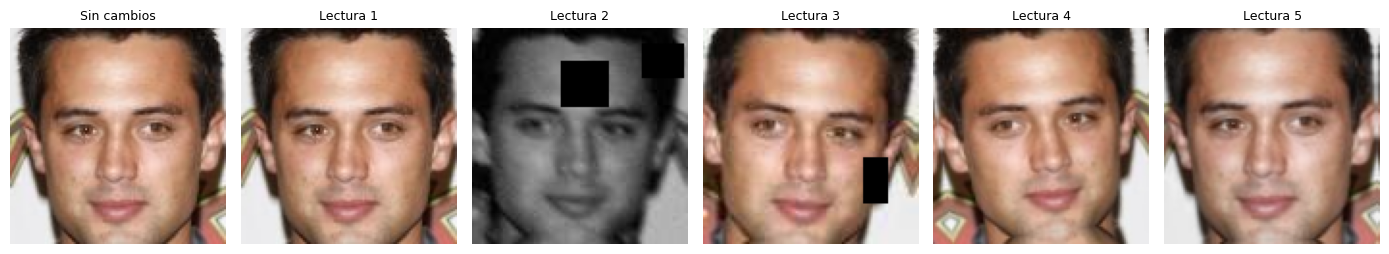

In [25]:
def a_imagen(x: torch.Tensor) -> np.ndarray:
    """Deshace el preprocesamiento para poder mostrar la foto."""
    return (x.numpy().transpose(1, 2, 0) * 127.5 + 127.5).clip(0, 255).astype(np.uint8)


fotos = [datos_train_a.imagenes[0]] + [a_imagen(datos_train_a[0][0]) for _ in range(5)]
titulos = ["Sin cambios"] + [f"Lectura {k}" for k in range(1, 6)]

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
for ax, foto, titulo in zip(axes, fotos, titulos):
    ax.imshow(foto)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

La primera es la foto sin cambios, que es como la ve validación. Cada lectura de train sale distinta: la 1 casi no cambia, la 2 quedó en blanco y negro, borrosa y con dos rectángulos negros, la 3 tiene otro rectángulo sobre la mejilla, y la 4 y la 5 tienen otra luz y están un poco corridas. En todas se sigue reconociendo a la misma persona, que es lo que buscamos: variaciones que podrían aparecer en una foto real sin cambiar la identidad.

### Entrenamiento

Estos son los hiperparámetros y por qué los elegimos:

| Hiperparámetro | Valor | Por qué |
|---|---|---|
| Optimizador | AdamW | Ajusta el paso de cada peso según sus gradientes y funciona bien con valores estándar, sin tener que buscar mucho el learning rate. A diferencia de Adam, aplica el weight decay directo sobre los pesos, así que regulariza a todos por igual |
| Learning rate inicial | 0,001 | El valor estándar para Adam y AdamW |
| Weight decay | 0,01 | El valor por defecto de AdamW en PyTorch. Empuja los pesos a quedarse chicos y ayuda contra el overfitting |
| Scheduler | ReduceLROnPlateau, divide por 10 si no mejora en 3 épocas | Pasos largos al principio y cortos al final. No sabemos cuántas épocas necesita la red, así que preferimos que baje el learning rate cuando la validación se estanca en lugar de fijar las épocas de antemano, como en StepLR o con coseno |
| Early stopping | Corta si no mejora en 8 épocas | Le damos más paciencia que al scheduler para que la red aproveche el learning rate más chico antes de cortar |
| Checkpoint | El de mejor accuracy de validación | Las épocas siguientes ya pueden estar sobreajustadas |
| Batch size | 128 | Suficientes fotos para que BatchNorm calcule medias y desvíos estables, y entra en la memoria de la GPU |
| Épocas | Máximo 200 | Es un tope de seguridad, lo normal es que corte antes el early stopping. Primero probamos con 40 y las dos redes llegaron al tope sin dejar de mejorar |

Para el scheduler, el early stopping y el checkpoint miramos la accuracy de validación y no la pérdida. Con el margen de ArcFace la pérdida cambia de escala, como vimos en la prueba de la cabeza, y la accuracy significa lo mismo en los dos experimentos.

Entrenamos en GPU si hay una disponible y si no en CPU.

In [26]:
BATCH_SIZE = 128
EPOCAS_MAX = 200
LR = 1e-3
WEIGHT_DECAY = 1e-2
PACIENCIA_LR = 3
PACIENCIA_PARADA = 8

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {device}" + (f" ({torch.cuda.get_device_name()})" if device == "cuda" else ""))

# En Windows los workers no pueden usar un Dataset definido en la notebook, así que cargamos en el proceso principal
cargador_train = DataLoader(datos_train_a, batch_size=BATCH_SIZE, shuffle=True,
                            generator=torch.Generator().manual_seed(SEED))
cargador_val = DataLoader(datos_val_a, batch_size=BATCH_SIZE)
print(f"Lotes por época: {len(cargador_train)} de train y {len(cargador_val)} de validación")

Dispositivo: cuda (NVIDIA GeForce RTX 2060)
Lotes por época: 99 de train y 22 de validación


Entrenamos en la GPU, una RTX 2060. Cada época son 99 lotes de train y 22 de validación.

La función `una_epoca` recorre todas las fotos una vez. Con optimizador entrena, y sin optimizador solo evalúa, sin Dropout y sin calcular gradientes. La pérdida es la que optimiza la red, con el margen incluido, tanto en train como en validación, para que las dos curvas sean comparables. La accuracy la calculamos sin margen, eligiendo a la persona con el coseno más alto, que es lo que haría la cabeza con cualquier foto.

La función `entrenar` arma la red y la cabeza, entrena hasta que corta el early stopping y guarda los pesos de la mejor época junto con el historial de cada época. Si el archivo ya existe lo carga y no entrena. Así la notebook se puede correr sin GPU en pocos minutos y las curvas se pueden dibujar igual, porque el historial queda guardado. Los archivos `.pth` no se suben al repositorio, así que hay que copiarlos a `models/modelo_a/`.

In [27]:
def una_epoca(modelo: nn.Module, cabeza: nn.Module, cargador: DataLoader, optimizador=None) -> tuple[float, float]:
    """Recorre el cargador una vez. Entrena si recibe un optimizador y si no solo evalúa."""
    entrenando = optimizador is not None
    modelo.train(entrenando)
    perdida_total, aciertos = 0.0, 0
    with torch.set_grad_enabled(entrenando):
        for x, y in cargador:
            x, y = x.to(device), y.to(device)
            embeddings = modelo(x)
            perdida = F.cross_entropy(cabeza(embeddings, y), y)
            if entrenando:
                optimizador.zero_grad()
                perdida.backward()
                optimizador.step()
            perdida_total += perdida.item() * len(y)
            aciertos += (cabeza(embeddings.detach()).argmax(dim=1) == y).sum().item()
    return perdida_total / len(cargador.dataset), aciertos / len(cargador.dataset)


def entrenar(m: float, ruta: Path) -> tuple[CustomCNN, pd.DataFrame]:
    """Entrena el modelo A con margen m, o lo carga de ruta si ya fue entrenado."""
    if ruta.exists():
        print(f"Cargamos el entrenamiento guardado en {ruta}")
        guardado = torch.load(ruta, map_location="cpu")
    else:
        torch.manual_seed(SEED)
        modelo = CustomCNN().to(device)
        cabeza = CabezaCoseno(modelo.embedding.out_features, n_personas_train, m=m).to(device)
        optimizador = torch.optim.AdamW([*modelo.parameters(), *cabeza.parameters()], lr=LR, weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="max", factor=0.1, patience=PACIENCIA_LR)

        historial, mejor_acc, sin_mejorar = [], 0.0, 0
        for epoca in range(1, EPOCAS_MAX + 1):
            inicio, lr = time.perf_counter(), optimizador.param_groups[0]["lr"]
            perdida_train, acc_train = una_epoca(modelo, cabeza, cargador_train, optimizador)
            perdida_val, acc_val = una_epoca(modelo, cabeza, cargador_val)
            historial.append({"epoca": epoca, "lr": lr, "perdida_train": perdida_train, "acc_train": acc_train,
                              "perdida_val": perdida_val, "acc_val": acc_val, "segundos": time.perf_counter() - inicio})
            print(f"Época {epoca:2d} | lr {lr:.0e} | pérdida {perdida_train:.3f} / {perdida_val:.3f} "
                  f"| accuracy {acc_train:.3f} / {acc_val:.3f} | {historial[-1]['segundos']:.0f} s")

            scheduler.step(acc_val)
            if acc_val > mejor_acc:
                mejor_acc, sin_mejorar = acc_val, 0
                mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
            else:
                sin_mejorar += 1
                if sin_mejorar == PACIENCIA_PARADA:
                    break

        guardado = {"m": m, "pesos": mejores_pesos, "historial": historial}
        ruta.parent.mkdir(parents=True, exist_ok=True)
        torch.save(guardado, ruta)

    modelo = CustomCNN()
    modelo.load_state_dict(guardado["pesos"])
    return modelo.eval(), pd.DataFrame(guardado["historial"]).set_index("epoca")

Primero entrenamos con `m = 0`, el softmax con cosenos. En cada época se ve la pérdida y la accuracy de train y de validación, en ese orden.

In [28]:
modelo_a_softmax, historial_softmax = entrenar(m=0.0, ruta=MODELS_DIR / "modelo_a" / "modelo_a_softmax.pth")
historial_softmax.round(3)

Cargamos el entrenamiento guardado en models\modelo_a\modelo_a_softmax.pth


,lr,perdida_train,acc_train,perdida_val,acc_val,segundos
epoca,,,,,,
1,0.001,7.718,0.001,7.047,0.003,21.195
2,0.001,6.889,0.002,6.679,0.003,20.163
3,0.001,6.637,0.003,6.549,0.004,20.071
4,0.001,6.532,0.004,6.497,0.003,20.118
5,0.001,6.463,0.004,6.400,0.006,20.140
...,...,...,...,...,...,...
79,0.000,0.294,0.955,1.392,0.697,21.257
80,0.000,0.280,0.957,1.385,0.697,21.333
81,0.000,0.278,0.957,1.380,0.699,21.369


El early stopping cortó en la época 83. La mejor fue la 75, con 70,2% de accuracy en validación y 95,0% en train. El learning rate bajó dos veces, en las épocas 72 y 80. Cada época tardó unos 21 segundos, unos 29 minutos en total.

Antes habíamos probado con un tope de 40 épocas, y la red llegó al tope con 47,0% en validación y sin dejar de mejorar: el learning rate nunca había bajado. Por eso subimos el tope.

Ahora entrenamos con `m = 0,5`, ArcFace, con todo lo demás igual.

In [29]:
modelo_a_arcface, historial_arcface = entrenar(m=0.5, ruta=MODELS_DIR / "modelo_a" / "modelo_a_arcface.pth")
historial_arcface.round(3)

Cargamos el entrenamiento guardado en models\modelo_a\modelo_a_arcface.pth


,lr,perdida_train,acc_train,perdida_val,acc_val,segundos
epoca,,,,,,
1,0.001,22.030,0.002,21.373,0.003,21.460
2,0.001,21.214,0.002,21.020,0.004,21.382
3,0.001,20.966,0.003,20.862,0.006,21.401
4,0.001,20.850,0.005,20.804,0.004,21.368
5,0.001,20.781,0.004,20.733,0.005,21.362
...,...,...,...,...,...,...
95,0.000,7.687,0.925,10.591,0.720,21.518
96,0.000,7.624,0.929,10.563,0.719,20.956
97,0.000,7.669,0.929,10.565,0.717,21.102


ArcFace tardó un poco más en cortar, en la época 99. La mejor fue la 91, con 72,0% de accuracy en validación y 92,3% en train. El learning rate bajó en las épocas 77 y 96. La pérdida está en otra escala que la del softmax, entre 22 y 8, porque el margen hace más difícil la tarea, como vimos al probar la cabeza. Con el tope de 40 épocas había llegado a 42,5%.

### Curvas de entrenamiento

Dibujamos la pérdida y la accuracy de train y de validación en cada época, para los dos experimentos. Las líneas grises punteadas marcan las épocas en que el scheduler bajó el learning rate, y la verde la época que guardamos.

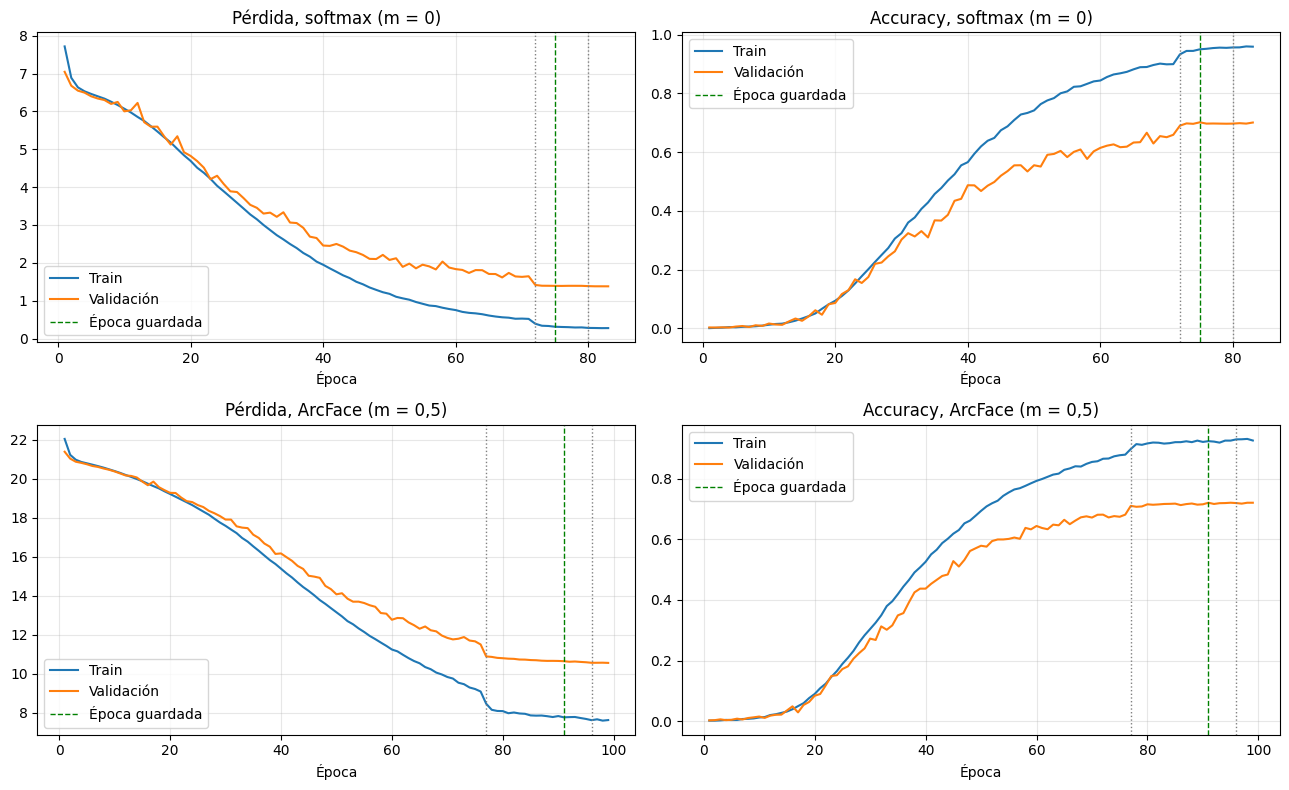

In [30]:
def graficar_curvas(historial: pd.DataFrame, axes, nombre: str) -> None:
    """Pérdida y accuracy de train y validación por época."""
    for ax, columna, titulo in [(axes[0], "perdida", "Pérdida"), (axes[1], "acc", "Accuracy")]:
        ax.plot(historial.index, historial[f"{columna}_train"], label="Train")
        ax.plot(historial.index, historial[f"{columna}_val"], label="Validación")
        for epoca in historial.index[historial["lr"].diff() < 0]:
            ax.axvline(epoca, color="gray", ls=":", lw=1)
        ax.axvline(historial["acc_val"].idxmax(), color="green", ls="--", lw=1, label="Época guardada")
        ax.set_title(f"{titulo}, {nombre}")
        ax.set_xlabel("Época")
        ax.grid(alpha=0.3)
        ax.legend()


fig, axes = plt.subplots(2, 2, figsize=(13, 8))
graficar_curvas(historial_softmax, axes[0], "softmax (m = 0)")
graficar_curvas(historial_arcface, axes[1], "ArcFace (m = 0,5)")
plt.tight_layout()
plt.show()

Las dos redes se comportan parecido. Durante unas 15 épocas casi no aprenden, y después train y validación suben juntas hasta la época 25 más o menos. Desde ahí train sigue subiendo más rápido que validación y la distancia entre las dos curvas crece: la red empieza a memorizar las fotos de train. Al final la distancia es de unos 25 puntos con softmax (95% contra 70%) y de unos 20 con ArcFace (92% contra 72%).

No llega a ser un overfitting que perjudique, porque la validación nunca baja: se aplana. En las dos se ve el efecto del scheduler. Cuando el learning rate baja por primera vez (épocas 72 y 77) hay un escalón: la pérdida de validación cae de golpe y la accuracy sube unos 3 puntos, de 65,9% a 69,0% con softmax y de 68,1% a 71,0% con ArcFace. La segunda bajada ya no cambia nada y el early stopping corta en la meseta.

### Elección entre experimentos

La accuracy del closed-set mide si la cabeza reconoce a las 696 personas de train. Pero la cabeza se descarta, y la app no trabaja con esas personas: compara los embeddings de gente nueva. Un modelo podría reconocer muy bien a las personas de train y aun así generar malos embeddings para personas que nunca vio. Por eso la accuracy del closed-set la usamos solo para controlar el entrenamiento, y para elegir entre los experimentos medimos lo que hace la app con las personas de validación open-set, igual que con el modelo B:

- Verificación: AUC, EER y TAR @ FAR = 1e-2 con los mismos pares de validación.
- Identificación: Top-1 de las consultas de personas registradas.
- El umbral de cada modelo calibrado con FAR de la app ≤ 1%, y el FRR que resulta con ese umbral.

Cada modelo necesita su propio umbral porque sus similitudes tienen otra escala. Agregamos al modelo B como referencia. El test no lo usamos: queda para evaluar una sola vez el modelo elegido.

In [31]:
def embeddings_modelo_a(modelo: CustomCNN, df: pd.DataFrame) -> np.ndarray:
    """Embeddings del modelo A para las fotos de df, sin augmentation."""
    modelo = modelo.to(device).eval()
    with torch.no_grad():
        return torch.cat([modelo(x.to(device)).cpu() for x, _ in DataLoader(RostrosDataset(df), batch_size=256)]).numpy()


def evaluar_en_val(embeddings: np.ndarray, historial: pd.DataFrame | None = None) -> dict:
    """Métricas de verificación e identificación en validación open-set, con el umbral propio del modelo."""
    verificacion = metricas_verificacion(similitudes_pares(embeddings, par_a_val, par_b_val), etiquetas_val)
    consultas = simular_app(val, embeddings)
    conocidas = consultas[~consultas["desconocido"]]
    umbral = elegir_umbral(consultas)
    far, frr = curvas_app(consultas, np.array([umbral]))
    return {"Épocas": len(historial) if historial is not None else np.nan,
            "Accuracy val closed-set": historial["acc_val"].max() if historial is not None else np.nan,
            "AUC": verificacion["AUC"], "EER": verificacion["EER"],
            "TAR @ FAR=0.01": verificacion["TAR @ FAR=0.01"],
            "Top-1": (conocidas["prediccion"] == conocidas["identity"]).mean(),
            "Umbral": umbral, "FAR app": far[0], "FRR app": frr[0]}


embeddings_val = {"Softmax (m = 0)": embeddings_modelo_a(modelo_a_softmax, val),
                  "ArcFace (m = 0,5)": embeddings_modelo_a(modelo_a_arcface, val)}
experimentos = pd.DataFrame({"Softmax (m = 0)": evaluar_en_val(embeddings_val["Softmax (m = 0)"], historial_softmax),
                             "ArcFace (m = 0,5)": evaluar_en_val(embeddings_val["ArcFace (m = 0,5)"], historial_arcface),
                             "Modelo B (referencia)": evaluar_en_val(embeddings_b_val)}).T
experimentos.round(4)

,Épocas,Accuracy val closed-set,AUC,EER,TAR @ FAR=0.01,Top-1,Umbral,FAR app,FRR app
Softmax (m = 0),83.0,0.7017,0.9361,0.1401,0.5061,0.5648,0.76,0.008,0.9060
"ArcFace (m = 0,5)",99.0,0.7202,0.9201,0.1590,0.4729,0.5329,0.71,0.008,0.9376
Modelo B (referencia),NaN,NaN,0.9991,0.0031,0.9975,0.9993,0.31,0.008,0.0019


ArcFace tiene más accuracy en el closed-set (72,0% contra 70,2%), pero con las personas nuevas es peor en todas las métricas: EER de 15,9% contra 14,0%, TAR @ FAR = 1e-2 de 47,3% contra 50,6%, Top-1 de 53,3% contra 56,5% y FRR de la app de 93,8% contra 90,6%. Es justamente el caso por el que no elegimos con la accuracy del closed-set: reconocer mejor a las personas de train no significó mejores embeddings para gente nueva. Por eso nos quedamos con el softmax como modelo A.

Una explicación posible es que el margen de 0,5 es demasiado exigente para una red chica y con pocas fotos por persona, y la red se ajusta más a las personas de train. Hay que tener en cuenta que entrenamos una sola vez cada experimento, y con otra semilla una diferencia de 2 o 3 puntos podría cambiar.

La diferencia con el modelo B es enorme. Su EER es de 0,3% contra 14,0%, y con un FAR de la app de 1% rechaza al 0,2% de los registrados, mientras que el modelo A rechaza al 90,6%. Con el umbral que pide ese nivel de seguridad (0,76), el modelo A no reconocería a casi nadie. Era lo esperable: el modelo B tiene 36 veces más parámetros y se entrenó con millones de fotos, y el nuestro con 12.595.